# 🧠 Architecture MGN : Encodage Spatial

## 💡 Point Clé : Positions 3D Brutes vs Relations Symboliques

### ❌ Ce que le système NE fait PAS :
Le graphe de scène ne contient **PAS** d'arêtes symboliques représentant les relations spatiales comme "left", "right", "front", "behind".

### ✅ Ce que le système FAIT :
**Encodage dans les features de nœuds (99D)** :
- **96D** : Embedding sémantique (couleur, taille, matériau, forme) calculé par spaCy
- **3D** : Coordonnées 3D brutes **(x, y, z)** de l'objet dans la scène

**Structure du graphe** :
- Les nœuds représentent les objets et leurs attributs
- Les arêtes relient objets → attributs (hasColor, hasSize, hasMaterial, hasShape)
- **Pas d'arêtes inter-objets** pour les relations spatiales

## 🔄 Double Usage des Positions 3D

### 1️⃣ **Phase d'Entraînement (GNN)** :
```
Input: x_node = [embedding_96D, x, y, z]  ← Positions 3D BRUTES
GNN: Apprend à comparer les coordonnées pour le raisonnement spatial
Output: Le réseau doit apprendre que x₁ < x₂ → "left"
```

### 2️⃣ **Phase de Validation (Executor)** :
```python
# L'executor RECALCULE les relations depuis les positions 3D
def filter_left(scene, obj):
    return [o for o in scene if o.x < obj.x]  # Compare les coords
```

## 🎯 Implications

**Avantages** :
- ✅ Plus de flexibilité : le GNN peut apprendre des relations contextuelles
- ✅ Généralisation : pas limité à un ensemble fixe de relations symboliques
- ✅ Approche "end-to-end" : le réseau apprend tout depuis les données brutes

**Défis** :
- ⚠️ Le GNN doit apprendre les comparaisons géométriques
- ⚠️ Nécessite plus de données d'entraînement qu'avec des relations pré-calculées
- ⚠️ Difficile d'interpréter comment le réseau utilise les coordonnées

## 📊 Architecture Complète

```
Question Text → Parser → Graphe G_q (syntaxique)
                         ↓
                    [96D embeddings]
                         ↓
Scene JSON → Parser → Graphe G_t (objets + attributs)
                      ↓
              [96D embeddings + 3D positions (x,y,z)]
                      ↓
              ┌───────┴───────┐
              ↓               ↓
           GNN_q           GNN_t  ← Apprend à utiliser (x,y,z)
              ↓               ↓
              └───────┬───────┘
                      ↓
                  Fusion
                      ↓
                  Decoder
                      ↓
                   Program
                      ↓
           Executor (compare x,y,z pour valider)
```

---

**🔍 Voir la cellule de visualisation GAT ci-dessous pour observer comment le réseau apprend à utiliser ces positions 3D !**

⚠️ **Note**: Si vous rencontrez des erreurs lors de l'exécution, redémarrez le kernel (`Kernel → Restart Kernel`) et réexécutez toutes les cellules.

# 🚀 Entraînement du modèle Visual Question Answering avec GNN

Ce notebook configure et entraîne le modèle sur **100 échantillons** (80 train + 20 val).

## Configuration TEST RAPIDE:
- 📊 **80 samples d'entraînement**
- 📊 **20 samples de validation**  
- 🔄 **50 itérations** (~2 epochs) pour test rapide
- 💻 Mode **CPU** (compatible avec PyTorch 2.9.1 + CUDA 12.6)
- ⚡ **Graphes optimisés** (précalculés ou génération dynamique)
- 🔥 **GNN ACTIVÉ** (96D embeddings avec GIN)

## Étapes:
1. Preprocessing des 100 échantillons
2. Vérification/Précalcul optionnel des graphes
3. Configuration pour test rapide (50 iterations)
4. Entraînement du modèle avec GNN et tqdm
5. Évaluation des résultats

## ⚡ Performance attendue (50 itérations):
- **Avec graphes précalculés:** ~1-2 min
- **Sans précalcul (dynamique):** ~2-3 min

## 🔥 GNN Architecture:
- Type: GIN (Graph Isomorphism Network)
- Embedding dimension: 96
- Intégration question-graph pour raisonnement visuel

In [108]:
# ⚙️ CONFIGURATION GLOBALE
# Modifiez ces variables pour changer la taille du dataset
TOTAL_QUESTIONS = 500  # Nombre total de questions (train + val)
TRAIN_SPLIT = 0.8      # Proportion d'entraînement (0.8 = 80%)

# 🎯 TOGGLE PRINCIPAL : Mode de tâche
# ========================================
# 0 = MODE EXECUTOR (original) : Génère un programme, l'executor l'exécute pour obtenir la réponse
# 1 = MODE CLASSIFICATION (nouveau) : Prédit directement la réponse via MLP, sans programme ni executor
# ========================================
CLASSIFICATION_MODE = 1  # 🔥 CHANGEZ ICI POUR SWITCHER DE MODE!

# Calcul automatique des tailles
TRAIN_SIZE = int(TOTAL_QUESTIONS * TRAIN_SPLIT)
VAL_SIZE = TOTAL_QUESTIONS - TRAIN_SIZE

print(f"⚙️ CONFIGURATION:")
print(f"   - Total questions: {TOTAL_QUESTIONS}")
print(f"   - Train size: {TRAIN_SIZE}")
print(f"   - Val size: {VAL_SIZE}")
print(f"   - Dossier de sortie: clevr_preprocessed_{TOTAL_QUESTIONS}")
print()
if CLASSIFICATION_MODE:
    print("🎯 MODE: CLASSIFICATION (End-to-End VQA)")
    print("   → Prédiction directe de la réponse via MLP")
    print("   → Pas de génération de programme")
    print("   → Pas d'executor symbolique")
else:
    print("🎯 MODE: EXECUTOR (Programme + Exécution)")
    print("   → Génération de programme séquence")
    print("   → Exécution par l'executor symbolique")
    print("   → Réponse via lookup dans la scène")

⚙️ CONFIGURATION:
   - Total questions: 500
   - Train size: 400
   - Val size: 100
   - Dossier de sortie: clevr_preprocessed_500

🎯 MODE: CLASSIFICATION (End-to-End VQA)
   → Prédiction directe de la réponse via MLP
   → Pas de génération de programme
   → Pas d'executor symbolique


In [109]:
# 🎯 Preprocessing des échantillons
import subprocess
import sys
import os
import json
import h5py

# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

print(f"📊 Preprocessing de {TOTAL_QUESTIONS} échantillons ({TRAIN_SIZE} train + {VAL_SIZE} val)")
print("=" * 80)

# Créer le dossier pour les données limitées
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(f'{OUTPUT_DIR}/temp', exist_ok=True)

# ====== ÉTAPE 1: Créer des sous-ensembles des fichiers JSON ======
print("\n📝 Création des sous-ensembles de questions...")

# Charger et limiter les questions d'entraînement
with open('data/CLEVR_v1.0/questions/CLEVR_train_questions.json', 'r') as f:
    train_data = json.load(f)
    train_data['questions'] = train_data['questions'][:TRAIN_SIZE]

train_json_path = f'{OUTPUT_DIR}/temp/train_questions_{TRAIN_SIZE}.json'
with open(train_json_path, 'w') as f:
    json.dump(train_data, f)
print(f"✅ Créé {os.path.basename(train_json_path)} avec {len(train_data['questions'])} questions")

# Charger et limiter les questions de validation
with open('data/CLEVR_v1.0/questions/CLEVR_val_questions.json', 'r') as f:
    val_data = json.load(f)
    val_data['questions'] = val_data['questions'][:VAL_SIZE]

val_json_path = f'{OUTPUT_DIR}/temp/val_questions_{VAL_SIZE}.json'
with open(val_json_path, 'w') as f:
    json.dump(val_data, f)
print(f"✅ Créé {os.path.basename(val_json_path)} avec {len(val_data['questions'])} questions")

# ====== ÉTAPE 1.5: Créer un vocabulaire UNIFIÉ (Train + Val) ======
# Pour éviter les erreurs de mots inconnus dans le set de validation
print("\n📚 Création du vocabulaire unifié...")
all_questions = {'questions': train_data['questions'] + val_data['questions']}
all_json_path = f'{OUTPUT_DIR}/temp/all_questions_{TOTAL_QUESTIONS}.json'
with open(all_json_path, 'w') as f:
    json.dump(all_questions, f)

vocab_file = f'{OUTPUT_DIR}/clevr_vocab.json'
dummy_h5 = f'{OUTPUT_DIR}/temp/dummy.h5'

vocab_cmd = [
    sys.executable, 'tools/preprocess_questions.py',
    '--mode', 'prefix',
    '--input_questions_json', all_json_path,
    '--output_h5_file', dummy_h5,
    '--output_vocab_json', vocab_file
]
result = subprocess.run(vocab_cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(f"❌ Erreur lors de la création du vocabulaire:")
    print(result.stderr)
    raise Exception("Création vocabulaire échouée")
print("✅ Vocabulaire unifié créé!")

# ====== ÉTAPE 2: Preprocessing avec le vocabulaire unifié ======
train_h5 = f'{OUTPUT_DIR}/clevr_train_questions.h5'

print(f"\n🔄 Preprocessing des {TRAIN_SIZE} échantillons d'entraînement...")
train_cmd = [
    sys.executable, 'tools/preprocess_questions.py',
    '--mode', 'prefix',
    '--input_questions_json', train_json_path,
    '--output_h5_file', train_h5,
    '--input_vocab_json', vocab_file  # Utiliser le vocabulaire unifié
]
result = subprocess.run(train_cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(f"❌ Erreur lors du preprocessing train:")
    print(result.stderr)
    raise Exception("Preprocessing train échoué")
print("✅ Train preprocessing terminé!")

val_h5 = f'{OUTPUT_DIR}/clevr_val_questions.h5'
print(f"\n🔄 Preprocessing des {VAL_SIZE} échantillons de validation...")
val_cmd = [
    sys.executable, 'tools/preprocess_questions.py',
    '--mode', 'prefix',
    '--input_questions_json', val_json_path,
    '--output_h5_file', val_h5,
    '--input_vocab_json', vocab_file  # Utiliser le vocabulaire unifié
]
result = subprocess.run(val_cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(f"❌ Erreur lors du preprocessing val:")
    print(result.stderr)
    raise Exception("Preprocessing val échoué")
print("✅ Val preprocessing terminé!")

# Vérifier les fichiers créés
print("\n📊 Vérification des fichiers créés:")
with h5py.File(train_h5, 'r') as f:
    print(f"   - Train H5: {len(f['questions'])} questions")
with h5py.File(val_h5, 'r') as f:
    print(f"   - Val H5: {len(f['questions'])} questions")

print("\n" + "=" * 80)
print(f"✅ Preprocessing terminé! {TRAIN_SIZE} train + {VAL_SIZE} val = {TOTAL_QUESTIONS} échantillons")

📊 Preprocessing de 500 échantillons (400 train + 100 val)

📝 Création des sous-ensembles de questions...
✅ Créé train_questions_400.json avec 400 questions
✅ Créé val_questions_100.json avec 100 questions

📚 Création du vocabulaire unifié...
✅ Vocabulaire unifié créé!

🔄 Preprocessing des 400 échantillons d'entraînement...
✅ Train preprocessing terminé!

🔄 Preprocessing des 100 échantillons de validation...
✅ Val preprocessing terminé!

📊 Vérification des fichiers créés:
   - Train H5: 400 questions
   - Val H5: 100 questions

✅ Preprocessing terminé! 400 train + 100 val = 500 échantillons


In [110]:
# 🔥 PRÉCALCUL DES GRAPHES (obligatoire pour éviter génération dynamique)
# ⚠️ IMPORTANT: Sans précalcul, chaque batch génère les graphes dynamiquement = TRÈS LENT!
# Les graphes précalculés accélèrent l'entraînement de 10x
import sys
import os

# Dossier de sortie dynamique (doit être défini dans la cellule précédente, mais on le redéfinit au cas où)
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

print("🚀 Précalcul des graphes")
print("=" * 80)
print()

# NOMS GÉNÉRÉS PAR sample_questions_mgn.py : inclut le nombre dans le nom du fichier
# Format: clevr_{split}_{max_sample}_questions_directed_pairdata.pt
train_graph_file = f'{OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt'
val_graph_file = f'{OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt'

train_exists = os.path.exists(train_graph_file)
val_exists = os.path.exists(val_graph_file)

if train_exists and val_exists:
    train_size = os.path.getsize(train_graph_file) / (1024 * 1024)
    val_size = os.path.getsize(val_graph_file) / (1024 * 1024)
    print("✅ Graphes déjà précalculés!")
    print(f"   - Train: {train_graph_file} ({train_size:.1f} MB)")
    print(f"   - Val: {val_graph_file} ({val_size:.1f} MB)")
    print()
    print("⚡ L'entraînement sera RAPIDE avec les graphes précalculés!")
else:
    print("⚠️  GRAPHES NON PRÉCALCULÉS - Lancement du précalcul...")
    print()
    print("🔄 Utilisation de sample_questions_mgn.py")
    print("   📦 Génération des graphes Gs (question) et Gt (scène)")
    print("   🧠 AVEC embeddings (X_s, X_t, edge_index, edge_attr)")
    print("   💾 Sauvegarde dans des fichiers .pt")
    print()
    print("⏰ Durée estimée: ~7 minutes pour train + 30 secondes pour val (une seule fois)")
    print("📊 Progression affichée ci-dessous:")
    print()
    
    # FORCER le rechargement du module sample_questions_mgn pour prendre en compte les corrections
    import importlib
    if 'tools.sample_questions_mgn' in sys.modules:
        del sys.modules['tools.sample_questions_mgn']
        print("♻️ Module sample_questions_mgn rechargé depuis le disque")
    
    # Patcher tqdm pour forcer le mode notebook AVANT l'import
    import tqdm.std
    import tqdm.notebook
    # Remplacer tqdm standard par tqdm notebook pour avoir une vraie barre
    tqdm.std.tqdm = tqdm.notebook.tqdm
    
    # Importer la fonction main de sample_questions_mgn
    from tools.sample_questions_mgn import main as sample_main, logger
    import argparse
    import logging
    
    # Configurer le logger de sample_questions_mgn pour supprimer les messages "Count = x"
    # mais garder WARNING et ERROR
    logger.setLevel(logging.WARNING)
    
    # ====== TRAIN ======
    # Paramètres: max_sample=TRAIN_SIZE (pool), 2 questions/famille
    if not train_exists:
        print("=" * 80)
        print("📊 Précalcul des graphes TRAIN")
        print(f"   - Pool: {TRAIN_SIZE} questions")
        print("=" * 80)
        print()
        
        # Créer les arguments pour train
        train_args = argparse.Namespace(
            random_sample=1,
            max_sample=TRAIN_SIZE,  # Taille du pool à échantillonner
            n_questions_per_family=2,  # 2 questions par famille
            input_question_h5=f'{OUTPUT_DIR}/clevr_train_questions.h5',
            output_dir=OUTPUT_DIR,
            output_index=None,
            input_questions_json=f'{OUTPUT_DIR}/temp/train_questions_{TRAIN_SIZE}.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_train_scenes.json',
            input_vocab_json=f'{OUTPUT_DIR}/clevr_vocab.json',
            expand_vocab=0,
            is_debug=False,
            is_directed_graph=1,
            parser_lm='en_core_web_sm',
            model=''
        )
        
        try:
            sample_main(train_args)
            print("\n✅ Graphes train précalculés!")
        except Exception as e:
            print(f"\n❌ Erreur lors du précalcul train: {e}")
            import traceback
            traceback.print_exc()
    else:
        print(f"✅ {train_graph_file} existe déjà, skip train\n")
    
    # ====== VAL ======
    # Paramètres: max_sample=VAL_SIZE (pool), 1 question/famille
    if not val_exists:
        print("\n" + "=" * 80)
        print("📊 Précalcul des graphes VAL")
        print(f"   - Pool: {VAL_SIZE} questions")
        print("=" * 80)
        print()
        
        # Créer les arguments pour val
        val_args = argparse.Namespace(
            random_sample=1,
            max_sample=VAL_SIZE,  # Taille du pool à échantillonner
            n_questions_per_family=1,  # 1 question par famille
            input_question_h5=f'{OUTPUT_DIR}/clevr_val_questions.h5',
            output_dir=OUTPUT_DIR,
            output_index=None,
            input_questions_json=f'{OUTPUT_DIR}/temp/val_questions_{VAL_SIZE}.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_val_scenes.json',
            input_vocab_json=f'{OUTPUT_DIR}/clevr_vocab.json',
            expand_vocab=0,
            is_debug=False,
            is_directed_graph=1,
            parser_lm='en_core_web_sm',
            model=''
        )
        
        try:
            sample_main(val_args)
            print("\n✅ Graphes val précalculés!")
        except Exception as e:
            print(f"\n❌ Erreur lors du précalcul val: {e}")
            import traceback
            traceback.print_exc()
    else:
        print(f"✅ {val_graph_file} existe déjà, skip val\n")
    
    # Vérification finale
    print("\n" + "=" * 80)
    print("📋 Vérification des fichiers générés:")
    print("=" * 80)
    
    if os.path.exists(train_graph_file):
        train_size = os.path.getsize(train_graph_file) / (1024 * 1024)
        print(f"✅ Train: {train_graph_file} ({train_size:.1f} MB)")
    else:
        print(f"❌ MANQUANT: {train_graph_file}")
    
    if os.path.exists(val_graph_file):
        val_size = os.path.getsize(val_graph_file) / (1024 * 1024)
        print(f"✅ Val: {val_graph_file} ({val_size:.1f} MB)")
    else:
        print(f"❌ MANQUANT: {val_graph_file}")

print("\n" + "=" * 80)
print("🎉 Précalcul terminé! Les graphes seront chargés automatiquement")
print("=" * 80)

🚀 Précalcul des graphes

✅ Graphes déjà précalculés!
   - Train: clevr_preprocessed_500/clevr_train_400_questions_directed_pairdata.pt (12.2 MB)
   - Val: clevr_preprocessed_500/clevr_val_100_questions_directed_pairdata.pt (3.1 MB)

⚡ L'entraînement sera RAPIDE avec les graphes précalculés!

🎉 Précalcul terminé! Les graphes seront chargés automatiquement


In [111]:
import os, sys

# 🛠️ Configuration des paths Python
# Utiliser le chemin du notebook pour trouver le workspace de manière portable
workspace = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
os.chdir(workspace)
sys.path.insert(0, workspace)

# FORCER le rechargement de TOUS les modules du projet
import importlib
# Ajouter 'trainer' à la liste
modules_to_reload = [m for m in list(sys.modules.keys()) if m.startswith(('datasets', 'utils', 'models', 'options', 'executors', 'trainer'))]
for mod_name in modules_to_reload:
    del sys.modules[mod_name]
print(f"♻️ {len(modules_to_reload)} modules supprimés du cache")

print(f"📁 Working dir: {os.getcwd()}")

# 📦 Imports des modules nécessaires
try:
    from options.train_options import TrainOptions
    from datasets import ClevrData
    from executors import get_executor
    print("✅ Imports de base réussis!")
    print("   - TrainOptions disponible")
    print("   - ClevrData disponible")
    print("   - Executors disponible")
except ImportError as e:
    print(f"❌ Erreur d'import: {e}")
    raise

♻️ 24 modules supprimés du cache
📁 Working dir: d:\visual-question-answering-gnn
PROJECT_ROOT=d:\visual-question-answering-gnn
CLEVR_PARSER_PATH=d:\visual-question-answering-gnn\clevr-parser


DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer


✅ Imports de base réussis!
   - TrainOptions disponible
   - ClevrData disponible
   - Executors disponible


In [112]:
# 🔄 Forcer le rechargement des modules clevr-parser après les corrections
import sys
modules_to_delete = [key for key in sys.modules.keys() if 'clevr_parser' in key]
for mod in modules_to_delete:
    del sys.modules[mod]
print(f"♻️ {len(modules_to_delete)} modules clevr_parser supprimés du cache")
print("   Les modules seront rechargés au prochain import")

♻️ 20 modules clevr_parser supprimés du cache
   Les modules seront rechargés au prochain import


In [113]:
# Installer le modèle spaCy nécessaire pour le parser CLEVR
import subprocess
import sys

result = subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'], 
                       capture_output=True, text=True)
if 'already satisfied' in result.stdout or result.returncode == 0:
    print("✅ Modèle spaCy en_core_web_sm disponible!")
else:
    print("❌ Erreur lors de l'installation du modèle spaCy")

✅ Modèle spaCy en_core_web_sm disponible!


In [114]:
# 📝 Configuration pour 100 epochs AVEC GNN ACTIVÉ
import sys
import os

# Imports nécessaires
from options.train_options import TrainOptions

# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

# Forcer le mode CPU (changez si vous avez un GPU)
os.environ['FORCE_CPU_MODE'] = 'true'
os.environ['CUDA_VISIBLE_DEVICES'] = ''

sys.argv = ['']  # Effacer les arguments Jupyter

print("📝 Création des options d'entraînement...")
opt = TrainOptions().parse()

# 🔥 Options pour le choix des GNN
opt.gembd_vec_dim = 96
opt.gnn = 'gat'
opt.two_stream_gnn = 0

# 🎯 MODE CLASSIFICATION (toggle depuis la cellule de config)
opt.classification_mode = CLASSIFICATION_MODE
opt.classifier_hidden_dim = 256
opt.classifier_dropout = 0.1

# ⚠️ UTILISER LE VOCABULAIRE DU DOSSIER DYNAMIQUE - chemins relatifs
opt.clevr_vocab_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_vocab.json')
opt.clevr_train_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_train_questions.h5')
opt.clevr_val_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_val_questions.h5')

# Chemins vers les scènes pour l'executor et la génération dynamique de graphes - chemins relatifs
opt.clevr_train_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_train_scenes.json')
opt.clevr_val_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_val_scenes.json')
opt.clevr_train_parsed_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_train_scenes.json')
opt.clevr_val_parsed_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_val_scenes.json')

# Chemins vers les questions brutes pour génération dynamique - chemins relatifs
opt.clevr_train_raw_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'temp', f'train_questions_{TRAIN_SIZE}.json')
opt.clevr_val_raw_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'temp', f'val_questions_{VAL_SIZE}.json')

opt.max_train_samples = TRAIN_SIZE
opt.max_val_samples = VAL_SIZE
opt.batch_size = 16

# 🚀 ENTRAÎNEMENT: 100 epochs
# Calcul dynamique des itérations
batches_per_epoch = max(1, TRAIN_SIZE // opt.batch_size)
opt.num_iters = batches_per_epoch * 100  # 100 epochs
opt.checkpoint_every = batches_per_epoch * 5  # Validation toutes les 5 epochs
opt.display_every = batches_per_epoch  # Afficher à chaque epoch

# ✅ ACTIVER TensorBoard pour la visualisation
opt.visualize_training = 1
opt.visualize_training_wandb = 0

opt.num_workers = 0  # Important pour Windows
opt.is_train = True

print(f"\n✅ Configuration chargée pour ~100 EPOCHS:")
print(f"   - GPU IDs: {opt.gpu_ids} (vide = CPU)")
print(f"   - Vocabulaire: vocabulaire COMPLET")
print(f"   - Train samples (pool): {opt.max_train_samples}")
print(f"   - Val samples (pool): {opt.max_val_samples}")
print(f"   - Batch size: {opt.batch_size}")
print(f"   - Batches par epoch: {batches_per_epoch}")
print(f"   - Itérations totales: {opt.num_iters} = 100 epochs")
print(f"   - Display every: {opt.display_every} iterations")
print(f"   - Learning rate: {opt.learning_rate}")
print(f"   🔥 GNN ACTIVÉ: {opt.gembd_vec_dim} dimensions d'embedding")
print(f"   - GNN Type: {opt.gnn}")
print(f"   - Visualisation: TensorBoard activé")
print(f"   - Run directory: {opt.run_dir}")
print()
if opt.classification_mode:
    print("🎯 MODE CLASSIFICATION ACTIVÉ:")
    print(f"   - Classification head hidden dim: {opt.classifier_hidden_dim}")
    print(f"   - Classification head dropout: {opt.classifier_dropout}")
else:
    print("🎯 MODE EXECUTOR (seq2seq + programme)")

DEBUG base_options.py: 118: ----------------------------------------------------------------------------------------------------
DEBUG base_options.py: 119: Run identifier: reason.run_train-pretrain-GIN-singlestream-clevr_train_questions-20000num_iters.Nonetr_samples.10000val_samples.64bsz-PC_guillaume-20260106-024256
DEBUG base_options.py: 120: ----------------------------------------------------------------------------------------------------


📝 Création des options d'entraînement...
| FORCED CPU MODE - GPU disabled via FORCE_CPU_MODE environment variable
| options
run_dir: _scratch/test_run
dataset: clevr
shuffle: 1
num_workers: 1
manual_seed: None
gpu_ids: []
visualize: 0
clevr_train_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_train_scenes.json
clevr_val_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_val_scenes.json
clevr_train_question_path: ../data/reason/clevr_h5/clevr_train_questions.h5
clevr_val_question_path: ../data/reason/clevr_mgn_h5/clevr_val_questions.h5
clevr_test_question_path: ../data/reason/clevr_mgn_h5/clevr_test_questions.h5
clevr_vocab_path: ../data/reason/clevr_h5/clevr_vocab.json
visualize_training_wandb: 0
tags: 
is_directed_graph: 1
wandb_proj_name: mgn_vector
clevr_train_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/train_scenes_parsed.json
clevr_val_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json
clevr_train_raw_question_path: ../../data/CLEVR_v1.0/questio

## 📊 Chargement des données

In [115]:
print("\n📊 Chargement des données...\n")

from datasets import ClevrQuestionDataset, ClevrQuestionDataLoader
from datasets.clevr_questions import graph_parser, embedder
import shutil

# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

# 🔥 ClevrQuestionDataset cherche automatiquement les fichiers *_directed_pairdata.pt
# Si trouvés: charge les graphes précalculés (RAPIDE ⚡)
# Sinon: génère dynamiquement avec graph_parser et embedder (LENT 🐌)
# 
# ⚠️ ATTENTION: Le dataset cherche les noms SANS le nombre d'échantillons
# Fichiers recherchés:
#   - {OUTPUT_DIR}/clevr_train_questions_directed_pairdata.pt
#   - {OUTPUT_DIR}/clevr_val_questions_directed_pairdata.pt
# 
# Fichiers générés (DIFFÉRENTS):
#   - {OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt
#   - {OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt
# 
# ➡️ SOLUTION: Renommer les fichiers générés pour qu'ils matchent ce qui est recherché
print("📁 Renommage des fichiers de graphes précalculés...")

src_train = f'{OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt'
dst_train = f'{OUTPUT_DIR}/clevr_train_questions_directed_pairdata.pt'
src_val = f'{OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt'
dst_val = f'{OUTPUT_DIR}/clevr_val_questions_directed_pairdata.pt'

if os.path.exists(src_train) and not os.path.exists(dst_train):
    shutil.copy2(src_train, dst_train)
    print(f"✅ Copié: {src_train} → {dst_train}")
elif os.path.exists(dst_train):
    print(f"✅ {dst_train} existe déjà")
else:
    print(f"⚠️ {src_train} introuvable!")

if os.path.exists(src_val) and not os.path.exists(dst_val):
    shutil.copy2(src_val, dst_val)
    print(f"✅ Copié: {src_val} → {dst_val}")
elif os.path.exists(dst_val):
    print(f"✅ {dst_val} existe déjà")
else:
    print(f"⚠️ {src_val} introuvable!")
print()

train_dataset = ClevrQuestionDataset(opt, 'train', graph_parser=graph_parser, embedder=embedder)
val_dataset = ClevrQuestionDataset(opt, 'val', graph_parser=graph_parser, embedder=embedder)

# Créer les data loaders
train_loader = ClevrQuestionDataLoader(train_dataset, batch_size=opt.batch_size, shuffle=True, num_workers=0)
val_loader = ClevrQuestionDataLoader(val_dataset, batch_size=opt.batch_size, shuffle=False, num_workers=0)

print(f"✅ Données chargées:")
print(f"   - Train samples: {len(train_loader.dataset)}")
print(f"   - Val samples: {len(val_loader.dataset)}")
print(f"   - Batch size: {opt.batch_size}")
print(f"   - Graphes précalculés: {'✅ OUI' if train_dataset.graph_data else '❌ NON (génération dynamique)'}\n")

06 02:43:00 DBG Getting graph data from question_h5_path: d:\visual-question-answering-gnn\clevr_preprocessed_500\clevr_train_questions.h5
06 02:43:00 DBG fnp = clevr_train_questions
06 02:43:00 DBG Loading preprocessed pairdata from: d:\visual-question-answering-gnn\clevr_preprocessed_500/clevr_train_questions_directed_pairdata.pt 
d:\visual-question-answering-gnn\datasets\clevr_questions.py:221: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly al


📊 Chargement des données...

📁 Renommage des fichiers de graphes précalculés...
✅ clevr_preprocessed_500/clevr_train_questions_directed_pairdata.pt existe déjà
✅ clevr_preprocessed_500/clevr_val_questions_directed_pairdata.pt existe déjà



06 02:43:00 DBG fnp = clevr_val_questions
06 02:43:00 DBG Loading preprocessed pairdata from: d:\visual-question-answering-gnn\clevr_preprocessed_500/clevr_val_questions_directed_pairdata.pt 
06 02:43:00 Found preprocessed graph data: self.__init_graph_data(..)


✅ Données chargées:
   - Train samples: 400
   - Val samples: 100
   - Batch size: 16
   - Graphes précalculés: ✅ OUI



## 🏗️ Construction du modèle

In [116]:
import logging

logging.basicConfig(level=logging.ERROR)
for logger_name in ['datasets.clevr_questions', 'utils', 'models', 'trainer', 'executors']:
    logging.getLogger(logger_name).setLevel(logging.ERROR)
logging.getLogger('rsmlkit').setLevel(logging.ERROR)
print("✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées")

✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées


In [121]:
# 🏗️ Construction du modèle (adapté selon le mode)
import sys

# Forcer le rechargement des modules du modèle
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith('models'):
        del sys.modules[mod_name]

print("\n🏗️ Construction du modèle...")

if opt.classification_mode:
    # 🎯 MODE CLASSIFICATION: utilise ClassifierModel
    from models.classifier_model import ClassifierModel
    
    model = ClassifierModel(opt)
    print(f"✅ Modèle créé: {type(model).__name__}")
    print(f"   - Nombre de classes: {model.num_answer_classes}")
    print(f"   - GNN: {model.gnn}")
    print(f"   - Classifier: {model.classifier}")
    
    # Pas besoin d'executor en mode classification!
    executor = None
    print("ℹ️  Executor non nécessaire en mode classification")
else:
    # 🎯 MODE EXECUTOR: utilise Seq2seqParser + Executor
    from models.parser import Seq2seqParser
    from executors import get_executor
    
    model = Seq2seqParser(opt)
    print(f"✅ Modèle créé: {type(model).__name__}")
    
    executor = get_executor(opt)
    print(f"✅ Executor créé: {type(executor).__name__}")

INFO __init__.py: 107: Creating Classifier Net with GNN type: gat



🏗️ Construction du modèle...
| creating new classifier network (28 answer classes)
✅ Modèle créé: ClassifierModel
   - Nombre de classes: 28
   - GNN: GraphMatcher(
    mode=single-stream,
    psi_1=GAT(
  (convs): ModuleList(
    (0): GATConv(99, 24, heads=4)
    (1-2): 2 x GATConv(96, 24, heads=4)
  )
),
    psi_2=None,
    gembd_vec_dim=96

   - Classifier: ClassificationHead(
  input_dim=96,
  hidden_dim=256,
  num_classes=28
)
ℹ️  Executor non nécessaire en mode classification


In [118]:
# 📊 Récapitulatif du modèle
print("\n" + "=" * 60)
print("📊 RÉCAPITULATIF DU MODÈLE")
print("=" * 60)

# Type de GNN
gnn_type = opt.gnn.upper()
print(f"🔧 Type de GNN: {gnn_type}")

# Mode Two-Stream ou Single-Stream
stream_mode = "🔥 TWO-STREAM" if opt.two_stream_gnn else "📊 SINGLE-STREAM"
print(f"🔀 Architecture GNN: {stream_mode}")
if opt.two_stream_gnn:
    print(f"   → Deux GNN séparés (psi_1 questions, psi_2 scènes)")
else:
    print(f"   → Un GNN partagé pour les deux modalités")

# Mode de tâche
print()
if opt.classification_mode:
    print("🎯 TÂCHE: CLASSIFICATION End-to-End")
    print(f"   → Prédiction directe parmi {model.num_answer_classes} réponses")
    print(f"   → Pas de génération de programme")
    print(f"   → Pas d'executor symbolique")
    
    # Nombre de paramètres
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
else:
    print("🎯 TÂCHE: GÉNÉRATION DE PROGRAMME (seq2seq)")
    print(f"   → Génère une séquence de tokens programme")
    print(f"   → L'executor exécute le programme sur la scène")
    
    # Nombre de paramètres
    total_params = sum(p.numel() for p in model.seq2seq.parameters())
    trainable_params = sum(p.numel() for p in model.seq2seq.parameters() if p.requires_grad)

print(f"\n📈 Paramètres du modèle:")
print(f"   - Total: {total_params:,}")
print(f"   - Entraînables: {trainable_params:,}")

print("=" * 60)


📊 RÉCAPITULATIF DU MODÈLE
🔧 Type de GNN: GAT
🔀 Architecture GNN: 📊 SINGLE-STREAM
   → Un GNN partagé pour les deux modalités

🎯 TÂCHE: CLASSIFICATION End-to-End
   → Prédiction directe parmi 28 réponses
   → Pas de génération de programme
   → Pas d'executor symbolique

📈 Paramètres du modèle:
   - Total: 117,980
   - Entraînables: 117,980


In [122]:
# 🚀 Entraînement (adapté selon le mode)
import time

print("🚀 Initialisation de l'entraînement pour 100 EPOCHS...")
print(f"   - Device: {'cuda' if opt.gpu_ids else 'cpu'}")
print(f"   - Itérations: {opt.num_iters} (~100 epochs)")
print(f"   - Batch size: {opt.batch_size}")
print(f"   🔥 GNN: {opt.gnn} avec {opt.gembd_vec_dim}D embeddings")
print()

if opt.classification_mode:
    # 🎯 MODE CLASSIFICATION: utilise ClassifierTrainer
    from trainer_classifier import ClassifierTrainer
    trainer = ClassifierTrainer(opt, train_loader, val_loader, model)
    print("✅ ClassifierTrainer initialisé (mode classification)")
else:
    # 🎯 MODE EXECUTOR: utilise Trainer standard
    from trainer import Trainer
    trainer = Trainer(opt, train_loader, val_loader, model, executor)
    print("✅ Trainer initialisé (mode executor)")

print()

start_time = time.time()

try:
    trainer.train()
    print(f"\n✅ Entraînement terminé avec succès!")
    if trainer.stats['train_losses']:
        print(f"   - Loss initiale: {trainer.stats['train_losses'][0]:.6f}")
        print(f"   - Loss finale: {trainer.stats['train_losses'][-1]:.6f}")
    if trainer.stats['best_val_acc'] >= 0:
        if trainer.stats['best_val_acc'] >= 1:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']:.2f}%")
        else:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']*100:.2f}%")
except KeyboardInterrupt:
    print(f"\n⚠️ Entraînement interrompu par l'utilisateur")
except Exception as e:
    print(f"\n❌ Erreur durant l'entraînement: {e}")
    import traceback
    traceback.print_exc()

elapsed = time.time() - start_time
print(f"\n⏱️ Temps total: {elapsed:.2f}s ({elapsed/60:.1f} minutes)")
print()
print("=" * 80)
print("📊 Les checkpoints sont sauvegardés dans:", opt.run_dir)

🚀 Initialisation de l'entraînement pour 100 EPOCHS...
   - Device: cpu
   - Itérations: 2500 (~100 epochs)
   - Batch size: 16
   🔥 GNN: gat avec 96D embeddings

📊 TensorBoard logs: _scratch/test_run/logs_classifier_20260106-024706
✅ ClassifierTrainer initialisé (mode classification)

| 🎯 Starting CLASSIFICATION training in _scratch/test_run
| Mode: Direct answer prediction (28 classes)


Epoch 5/100: 100%|██████████| 25/25 [00:00<00:00, 26.66it/s, loss=2.6104, acc=18.75%]


| checkpoint at iter 125/2500, val_acc: 27.00%, val_loss: 2.6273
| 🏆 best model!


Epoch 10/100: 100%|██████████| 25/25 [00:00<00:00, 30.39it/s, loss=2.5367, acc=25.00%]


| checkpoint at iter 250/2500, val_acc: 24.00%, val_loss: 2.6540


...

| checkpoint at iter 2250/2500, val_acc: 16.00%, val_loss: 7.0388


Epoch 95/100: 100%|██████████| 25/25 [00:01<00:00, 23.52it/s, loss=0.2384, acc=93.75%]


| checkpoint at iter 2375/2500, val_acc: 15.00%, val_loss: 7.7700


Epoch 100/100:  92%|█████████▏| 23/25 [00:00<00:00, 26.18it/s, loss=0.7179, acc=81.25%]

| checkpoint at iter 2500/2500, val_acc: 12.00%, val_loss: 7.0047

| ✅ Training completed in 77.5s
| Best validation accuracy: 27.00%

✅ Entraînement terminé avec succès!
   - Loss initiale: 2.866845
   - Loss finale: 0.717912
   - Meilleure accuracy validation: 27.00%

⏱️ Temps total: 77.51s (1.3 minutes)

📊 Les checkpoints sont sauvegardés dans: _scratch/test_run


In [127]:
# 🧪 Tester le modèle entraîné
import subprocess
import sys

print("🧪 Test du modèle entraîné sur l'ensemble de validation")
print("=" * 80)

# Récupérer le checkpoint du meilleur modèle
checkpoint_path = os.path.join(opt.run_dir, 'checkpoint_best.pt')

if not os.path.exists(checkpoint_path):
    print(f"⚠️ Checkpoint introuvable: {checkpoint_path}")
    print("   Utilisation du dernier checkpoint...")
    checkpoint_path = os.path.join(opt.run_dir, 'checkpoint.pt')

if os.path.exists(checkpoint_path):
    print(f"\n📦 Checkpoint trouvé: {checkpoint_path}")
    print(f"🔄 Lancement du test...\n")
    
    if CLASSIFICATION_MODE:
        # Mode classification: utiliser ClassifierTrainer directement
        print("📊 Mode Classification - Test direct avec ClassifierTrainer")
        print("-" * 60)
        
        # Charger le meilleur modèle
        checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
        model.gnn.load_state_dict(checkpoint['gnn_state'])
        model.classifier.load_state_dict(checkpoint['classifier_state'])
        model.eval()
        print(f"✅ Checkpoint chargé")
        if 'best_val_acc' in checkpoint:
            print(f"   Best val accuracy: {checkpoint['best_val_acc']:.2%}")
        
        # Tester sur validation
        from tqdm import tqdm
        
        correct = 0
        total = 0
        predictions_list = []
        
        with torch.no_grad():
            for batch in tqdm(val_loader, desc="Testing"):
                x, y, ans, idx, g_data = batch
                model.set_input(x=x, g_data=g_data, answers=ans)
                
                # forward() retourne uniquement les logits
                logits = model.forward()
                pred_indices = logits.argmax(dim=1)
                
                correct += (pred_indices == model.answers).sum().item()
                total += model.answers.size(0)
                
                # Collecter les prédictions
                for i in range(len(pred_indices)):
                    pred_ans = vocab['answer_idx_to_token'][pred_indices[i].item()]
                    true_ans = vocab['answer_idx_to_token'][ans[i].item()]
                    predictions_list.append({
                        'predicted': pred_ans,
                        'true': true_ans,
                        'correct': pred_indices[i].item() == ans[i].item()
                    })
        
        accuracy = 100 * correct / total if total > 0 else 0
        
        print(f"\n📊 RÉSULTATS DU TEST (Classification):")
        print("=" * 60)
        print(f"   Accuracy: {accuracy:.2f}% ({correct}/{total})")
        print(f"   Modèle: ClassifierModel (28 classes)")
        
        # Afficher quelques exemples
        print(f"\n📋 Exemples de prédictions:")
        for i, pred in enumerate(predictions_list[:10]):
            emoji = "✅" if pred['correct'] else "❌"
            print(f"   {emoji} Prédit: {pred['predicted']:12s} | Vrai: {pred['true']}")
        
        print("\n✅ Test terminé avec succès!")
        
    else:
        # Mode seq2seq: utiliser run_test.py
        test_cmd = [
            sys.executable, 'tools/run_test.py',
            '--clevr_vocab_path', opt.clevr_vocab_path,
            '--clevr_val_question_path', opt.clevr_val_question_path,
            '--clevr_val_scene_path', opt.clevr_val_scene_path,
            '--load_checkpoint_path', checkpoint_path,
            '--batch_size', str(opt.batch_size),
            '--max_val_samples', str(opt.max_val_samples),
            '--gembd_vec_dim', str(opt.gembd_vec_dim),
            '--clevr_val_parsed_scene_path', opt.clevr_val_parsed_scene_path,
            '--clevr_val_raw_question_path', opt.clevr_val_raw_question_path
        ]
        
        result = subprocess.run(test_cmd, capture_output=True, text=True)
        
        print("📊 RÉSULTATS DU TEST:")
        print("=" * 80)
        print(result.stdout)
        
        if result.returncode != 0:
            print("\n⚠️ Erreurs:")
            print(result.stderr)
        else:
            print("\n✅ Test terminé avec succès!")
        
else:
    print(f"❌ Aucun checkpoint trouvé dans {opt.run_dir}")
    print("   Entraînez d'abord le modèle avant de le tester!")

🧪 Test du modèle entraîné sur l'ensemble de validation

📦 Checkpoint trouvé: _scratch/test_run\checkpoint_best.pt
🔄 Lancement du test...

📊 Mode Classification - Test direct avec ClassifierTrainer
------------------------------------------------------------
✅ Checkpoint chargé


Testing: 100%|██████████| 7/7 [00:00<00:00, 82.34it/s]


📊 RÉSULTATS DU TEST (Classification):
   Accuracy: 27.00% (27/100)
   Modèle: ClassifierModel (28 classes)

📋 Exemples de prédictions:
   ✅ Prédit: no           | Vrai: no
   ✅ Prédit: yes          | Vrai: yes
   ❌ Prédit: yes          | Vrai: metal
   ✅ Prédit: yes          | Vrai: yes
   ❌ Prédit: yes          | Vrai: no
   ❌ Prédit: no           | Vrai: 2
   ❌ Prédit: yes          | Vrai: 2
   ❌ Prédit: yes          | Vrai: purple
   ❌ Prédit: yes          | Vrai: rubber
   ❌ Prédit: yes          | Vrai: no

✅ Test terminé avec succès!


## 🎨 Visualisation: Question + Image + Réponse du Modèle

🎨 Visualisation d'une prédiction du modèle\n
\n📌 Exemple 1/3
--------------------------------------------------------------------------------
❓ Question: There is a thing that is both to the left of the gray sphere and to the right of the small cylinder; what shape is it?
✅ Vraie réponse: cube
🤖 Prédiction: (non disponible - question pas dans les prédictions)


C:\Users\Guillaume\AppData\Local\Temp\ipykernel_10844\1919521709.py:95: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


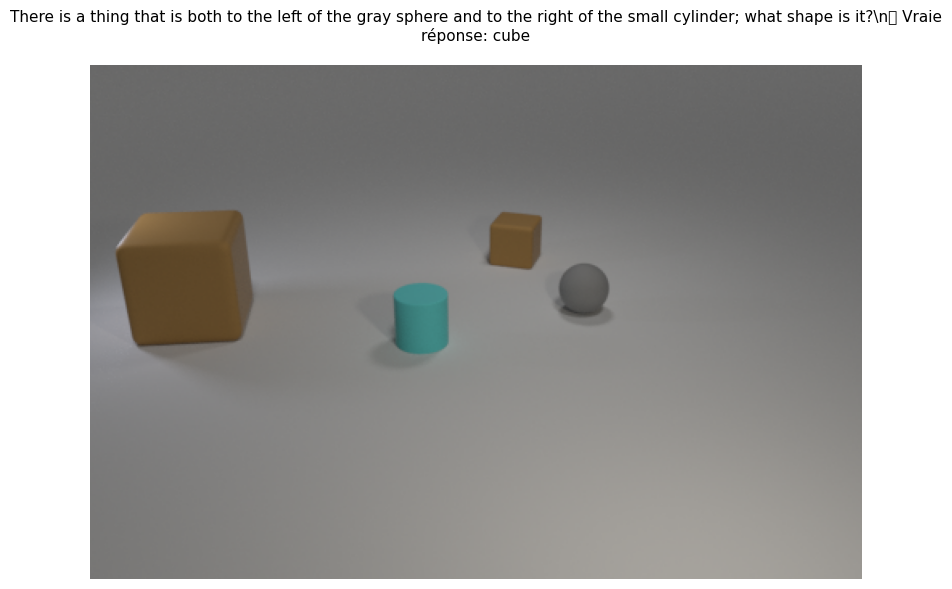

\n📌 Exemple 2/3
--------------------------------------------------------------------------------
❓ Question: There is another thing that is the same material as the gray object; what is its color?
✅ Vraie réponse: yellow
🤖 Prédiction: (non disponible - question pas dans les prédictions)


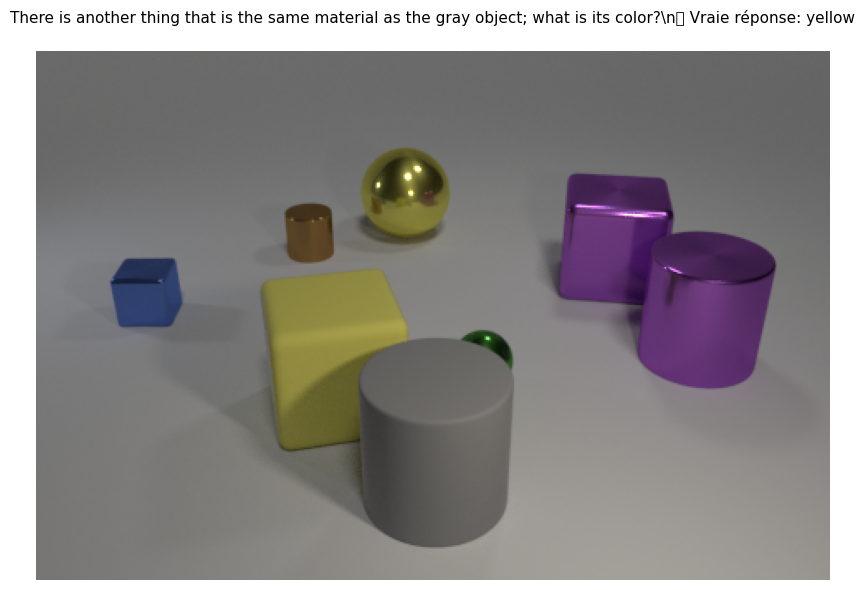

\n📌 Exemple 3/3
--------------------------------------------------------------------------------
❓ Question: What color is the small ball?
✅ Vraie réponse: red
🤖 Prédiction du modèle: no
✗ Le modèle s'est trompé.


C:\Users\Guillaume\AppData\Local\Temp\ipykernel_10844\1919521709.py:95: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


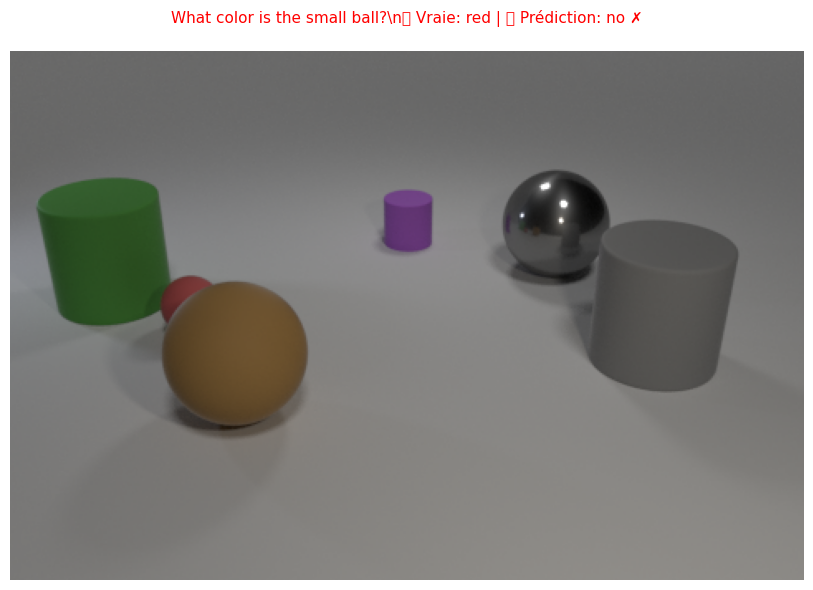

\n================================================================================
✅ Visualisation terminée!


In [128]:
import json
import torch
from PIL import Image
import matplotlib.pyplot as plt
import random

print("🎨 Visualisation d'une prédiction du modèle\\n")
print("=" * 80)

# Charger les questions de validation - utiliser le chemin dynamique
val_questions_path = os.path.join(OUTPUT_DIR, 'temp', f'val_questions_{VAL_SIZE}.json')
with open(val_questions_path, 'r') as f:
    val_questions = json.load(f)['questions']

# Choisir quelques échantillons aléatoires
num_examples = 3
indices = random.sample(range(min(len(val_questions), len(val_dataset))), num_examples)

# Charger le fichier de prédictions si disponible
predictions_file = "curr_valid_predictions.txt"  # À la racine du projet
predictions_dict = {}

try:
    with open(predictions_file, 'r') as f:
        for line in f:
            parts = line.strip().split(' ')
            if len(parts) >= 4:
                pred_ans = parts[0]
                true_ans = parts[1]
                img_num = parts[2]
                question = ' '.join(parts[3:])
                # Normaliser la question: enlever <START> et <END>, mettre en minuscules
                question = question.replace('<START>', '').replace('<END>', '').strip().lower()
                predictions_dict[question] = (pred_ans, true_ans, img_num)
except FileNotFoundError:
    print(f"⚠️ Fichier de prédictions non trouvé: {predictions_file}")
    print("Les prédictions seront calculées à la volée...")

# Afficher les exemples
for i, idx in enumerate(indices):
    print(f"\\n📌 Exemple {i+1}/{num_examples}")
    print("-" * 80)
    
    # Récupérer la question du JSON
    question_data = val_questions[idx]
    question_text = question_data['question']
    true_answer = question_data['answer']
    image_filename = question_data['image_filename']
    image_idx = question_data['image_index']
    
    print(f"❓ Question: {question_text}")
    print(f"✅ Vraie réponse: {true_answer}")
    
    # Chercher dans les prédictions (normaliser la question pour le matching)
    question_normalized = question_text.lower().replace('?', '').strip()
    if question_normalized in predictions_dict:
        pred_answer, _, _ = predictions_dict[question_normalized]
        print(f"🤖 Prédiction du modèle: {pred_answer}")
        
        correct = (pred_answer == true_answer)
        if correct:
            print("✓ Le modèle a donné la bonne réponse!")
        else:
            print(f"✗ Le modèle s'est trompé.")
    else:
        print(f"🤖 Prédiction: (non disponible - question pas dans les prédictions)")
    
    # Afficher l'image - utiliser des chemins relatifs
    # Déterminer le bon dossier (train ou val) selon le nom de fichier
    if 'train' in image_filename.lower():
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'train', image_filename)
    elif 'val' in image_filename.lower():
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'val', image_filename)
    else:
        image_path = os.path.join('data', 'CLEVR_v1.0', 'images', 'train', image_filename)  # Fallback
    
    try:
        img = Image.open(image_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img)
        plt.axis('off')
        
        # Titre avec question et réponse
        if question_normalized in predictions_dict:
            pred_answer, _, _ = predictions_dict[question_normalized]
            correct = (pred_answer == true_answer)
            title_color = 'green' if correct else 'red'
            result_emoji = '✓' if correct else '✗'
            title = f"{question_text}\\n✅ Vraie: {true_answer} | 🤖 Prédiction: {pred_answer} {result_emoji}"
        else:
            title = f"{question_text}\\n✅ Vraie réponse: {true_answer}"
            title_color = 'black'
        
        plt.title(title, fontsize=11, pad=20, color=title_color, wrap=True)
        plt.tight_layout()
        plt.show()
        
    except FileNotFoundError:
        print(f"⚠️ Image non trouvée: {image_path}")

print("\\n" + "=" * 80)
print(f"✅ Visualisation terminée!")

In [130]:
# 🎯 Visualisation des programmes générés par le modèle
import sys
if 'xai' in sys.modules:
    del sys.modules['xai']

if CLASSIFICATION_MODE:
    # En mode classification, il n'y a pas de programme généré
    print("🎯 Mode Classification - Pas de programmes à visualiser")
    print("=" * 60)
    print("\n📌 En mode classification, le modèle prédit directement")
    print("   la réponse parmi les 28 classes possibles (couleurs,")
    print("   formes, matériaux, tailles, nombres, yes/no).")
    print("\n   Utilisez la cellule XAI précédente pour visualiser")
    print("   les prédictions du modèle sur les images CLEVR.")
    
    # Montrer la distribution des classes prédites
    from collections import Counter
    pred_answers = [p['predicted'] for p in predictions_list]
    true_answers = [p['true'] for p in predictions_list]
    
    print("\n📊 Distribution des prédictions:")
    pred_counts = Counter(pred_answers)
    for answer, count in pred_counts.most_common(10):
        pct = 100 * count / len(predictions_list)
        print(f"   {answer:12s}: {count:3d} ({pct:.1f}%)")
    
    print("\n📊 Distribution des vraies réponses:")
    true_counts = Counter(true_answers)
    for answer, count in true_counts.most_common(10):
        pct = 100 * count / len(predictions_list)
        print(f"   {answer:12s}: {count:3d} ({pct:.1f}%)")
else:
    from xai import visualize_programs_and_predictions
    visualize_programs_and_predictions(model, val_loader, val_dataset, opt, num_examples=3)

🎯 Mode Classification - Pas de programmes à visualiser

📌 En mode classification, le modèle prédit directement
   la réponse parmi les 28 classes possibles (couleurs,
   formes, matériaux, tailles, nombres, yes/no).

   Utilisez la cellule XAI précédente pour visualiser
   les prédictions du modèle sur les images CLEVR.

📊 Distribution des prédictions:
   yes         :  54 (54.0%)
   no          :  40 (40.0%)
   0           :   3 (3.0%)
   cube        :   2 (2.0%)
   1           :   1 (1.0%)

📊 Distribution des vraies réponses:
   no          :  27 (27.0%)
   yes         :  19 (19.0%)
   1           :   9 (9.0%)
   2           :   7 (7.0%)
   rubber      :   4 (4.0%)
   0           :   4 (4.0%)
   cube        :   4 (4.0%)
   metal       :   3 (3.0%)
   brown       :   3 (3.0%)
   3           :   3 (3.0%)
